# SafeRoute 3D — Faz 2: Ön İşleme, Öznitelik Mühendisliği ve Öznitelik Seçimi

## 1. Faz 2'nin amacı

Faz 1'de ham veri değiştirilmeden ölçüldü. Faz 2'nin amacı, ham veriyi **hiç değiştirmeden**, Faz 3'teki
kümeleme deneyleri için savunulabilir, izlenebilir ve tekrarlanabilir bir veri katmanı üretmektir:

| Katman | İçerik |
|---|---|
| **raw** | İndirildiği gibi, salt-okunur (Faz 1) + resmî ilçe sınırları |
| **interim** | Türleri doğrulanmış, standartlaştırılmış; geçersizlik nedenleri korunmuş |
| **processed** | Tüm satırlar; kalite bayrakları, ilçe çıkarımı, zaman/araç/yaralanma öznitelikleri |
| **features** | Her algoritma için ayrı öznitelik matrisi (A: DBSCAN, B: K-Means, C: HDBSCAN, D: uzay-zaman) |

Bu defterdeki **tüm işlem mantığı `saferoute.preprocess` paketindedir**; defter aynı fonksiyonları çağırır,
mantığı yeniden yazmaz. Markdown hücrelerinde elle yazılmış istatistik yoktur; sayılar hücre çıktılarındadır.
Bu fazda **hiçbir model eğitilmez**.

In [1]:
import json, time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

from saferoute import config
from saferoute.data.loader import latest_snapshot, load_raw
from saferoute.preprocess import coordinates, features, temporal, vehicles
from saferoute.preprocess.boundaries import latest_boundaries, read_boundaries_snapshot
from saferoute.preprocess.pipeline import output_paths, run_pipeline
from saferoute.preprocess.report import STATUS_TR, write_reports
from saferoute.preprocess.settings import PreprocessConfig
from saferoute.perf import peak_memory_mb

pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 70)
FIG = config.REPORTS_DIR / "phase2" / "figures"
show = lambda name: display(Image(filename=str(FIG / name)))

SNAPSHOT, BOUNDS = latest_snapshot(), latest_boundaries()
cfg = PreprocessConfig()
print("Kaza anlık görüntüsü:", SNAPSHOT.name, "| İlçe sınırları:", BOUNDS.name)
print("Yapılandırma:", cfg.as_dict())

Kaza anlık görüntüsü: snapshot_20261019T155113Z | İlçe sınırları: snapshot_20261019T170733Z
Yapılandırma: {'nearshore_buffer_m': 500.0, 'clustering_include_nearshore': True, 'midnight_suspect_hour': 0, 'midnight_suspect_minute': 0, 'time_periods': ((0, 'night'), (6, 'morning'), (12, 'afternoon'), (18, 'evening')), 'projected_crs': 'EPSG:32618', 'geographic_crs': 'EPSG:4326', 'earth_radius_m': 6371008.8, 'top_repeated_locations': 25, 'extra': {}}


In [2]:
# Hattı çalıştır: girdiler + yapılandırma değişmediyse çıktılar doğrulanır ve adımlar atlanır (idempotent).
t0 = time.perf_counter()
summary = run_pipeline(SNAPSHOT, BOUNDS, cfg)
print(f"Atlandı mı: {summary['skipped']}  ({time.perf_counter() - t0:.1f} sn)")
print("Ham veri değişmedi:", summary["raw_unchanged"])
paths = output_paths(SNAPSHOT.name)
pd.DataFrame(summary["rows"], index=["kayıt"]).T

Çıktılar güncel (aynı kaynak + yapılandırma); hat atlandı.
Atlandı mı: True  (1.3 sn)
Ham veri değişmedi: True


,kayıt
raw,2269187
interim,2269187
processed,2269187
eligible_for_spatial_clustering,2020638
is_valid_geographic_record,2020638


## 2. Ham veri incelemesi ve Faz 1 ile tutarlılık

Faz 1 raporundaki sayılar **sabit kodlanmadan** bu koşuda ham veriden yeniden hesaplanır ve karşılaştırılır.

In [3]:
pd.DataFrame(summary["phase1_crosscheck"]).T

,phase1,phase2,match
row_count,2269187,2269187,True
column_count_raw,29,29,True
valid_coordinates_bbox,2020640,2020640,True
missing_coordinates,240806,240806,True
zero_coordinates,7591,7591,True
outside_bbox,150,150,True
borough_missing,691375,691375,True
valid_bbox_borough_missing,487026,487026,True
distinct_valid_locations_bbox,349124,349124,True
midnight_records,24566,24566,True


## 3. Eksik veri analizi

Eksik değerler **doldurulmaz** (imputation yapılmaz). Bunun gerekçesi: koordinat, ilçe veya saat için
uydurulan bir değer, mekânsal kümelemede gerçekte olmayan yoğunluklar üretir. Eksikler ya (a) güvenilir bir
dış kaynaktan **çıkarılır** (ilçe ← resmî poligon), ya (b) bayrakla işaretlenir, ya da (c) yalnızca o bilgiyi
gerektiren analizden **gerekçesiyle** dışlanır.

In [4]:
raw_missing = pd.Series(summary["standardize"]["raw_missing_pct"], name="Ham eksik %").sort_values(ascending=False)
raw_missing.to_frame().head(15)

,Ham eksik %
vehicle_type_code_5,99.5598
contributing_factor_vehicle_5,99.5455
vehicle_type_code_4,98.4028
contributing_factor_vehicle_4,98.3416
vehicle_type_code_3,93.0445
contributing_factor_vehicle_3,92.7556
cross_street_name,82.0739
off_street_name,38.3469
zip_code,30.4824
borough,30.4680


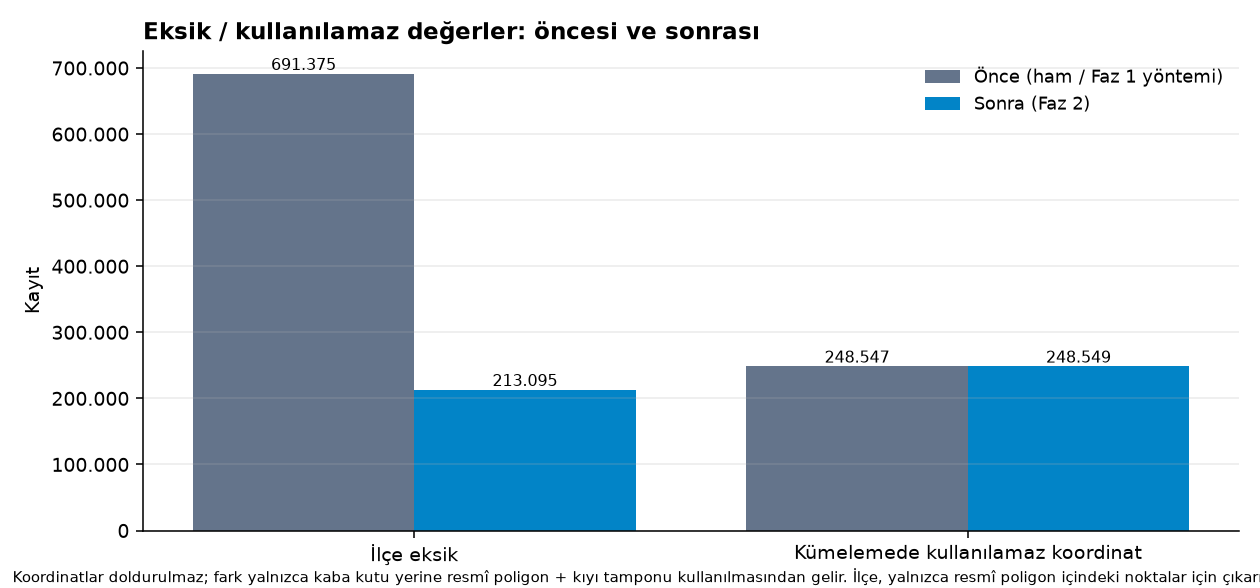

In [5]:
show("missing_before_after.png")

## 4. Coğrafi koordinat temizliği

Her kayda **tek bir** `coordinate_quality_status` atanır (öncelik sırasıyla): eksik → ayrıştırılamaz →
sonlu değil → sıfır → geçersiz aralık → NYC dışı (uzak) → poligon dışı kıyıya yakın → sınırda belirsiz →
resmî ilçe sınırı içinde. Kıyıya yakınlık eşiği gerçek mesafe dağılımından seçilmiştir (aşağıdaki kümülatif tablo).

In [6]:
c = summary["coordinates"]
status = pd.DataFrame({"Kayıt": c["status_counts"]})
status["Durum"] = [STATUS_TR[k] for k in status.index]
status["Oran %"] = (100 * status["Kayıt"] / summary["rows"]["raw"]).round(4)
display(status[["Durum", "Kayıt", "Oran %"]])
print("Poligon dışı noktaların NYC karasına uzaklığı — kümülatif:")
display(pd.Series(c["distance_outside_nyc_m"]["cumulative_within_m"], name="kayıt").to_frame().T)
print("Çakışan dışlama nedenleri:", c["overlapping_reasons"])

,Durum,Kayıt,Oran %
missing,Eksik,240806,10.6120
unparseable,Ayrıştırılamaz,0,0.0000
non_finite,Sonlu değil,0,0.0000
zero,"Sıfır (0,0)",7591,0.3345
invalid_range,Geçersiz aralık,106,0.0047
outside_nyc_far,NYC dışı (uzak),46,0.0020
outside_nyc_nearshore,"Poligon dışı, kıyıya yakın",9394,0.4140
boundary_ambiguous,Sınırda belirsiz,0,0.0000
valid_in_boundary,Resmî ilçe sınırı içinde,2011244,88.6328


Poligon dışı noktaların NYC karasına uzaklığı — kümülatif:


,25,50,100,200,300,500,1000,5000
kayıt,3442,5403,6732,8957,9294,9394,9394,9397


Çakışan dışlama nedenleri: {'coordinate_invalid_and_borough_missing': 204351, 'coordinate_invalid_and_midnight_suspect': 1850, 'coordinate_invalid_and_injury_flagged': 741}


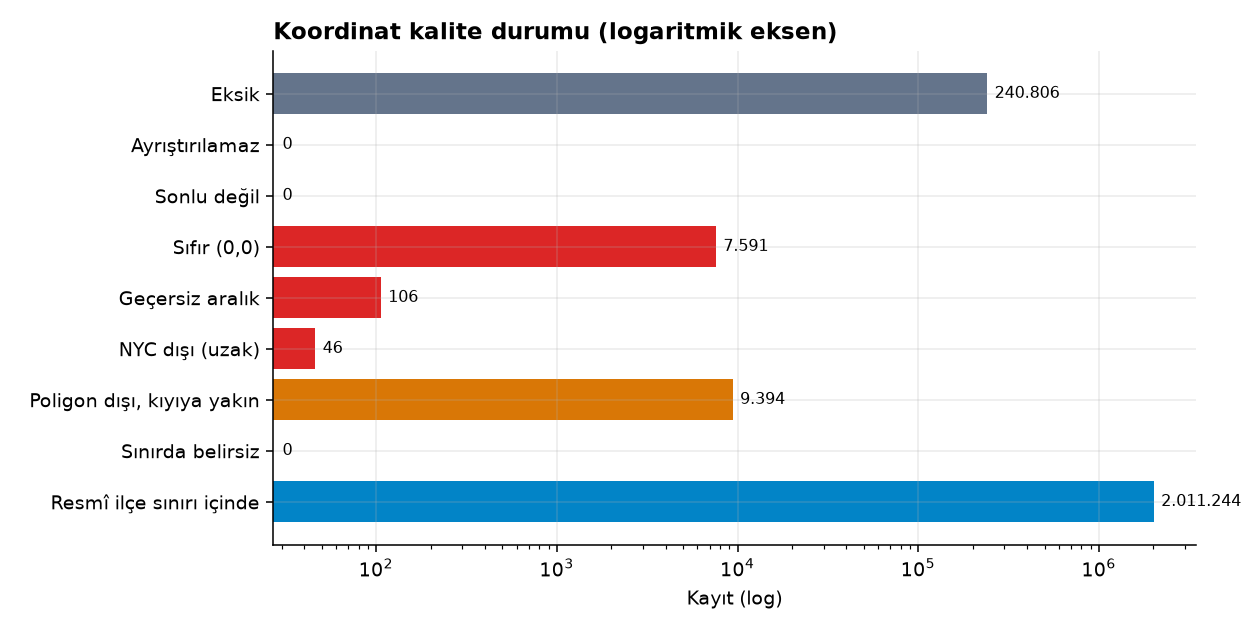

In [7]:
show("coordinate_quality_status.png")

**Yorum.** Mesafe dağılımında 500–1000 m arasında hiç nokta yoktur; bu doğal kırılma, kıyı tamponu için
500 m seçiminin veriye dayalı gerekçesidir. Poligon dışındaki noktaların önemli kısmı köprü ve kıyı
yollarıdır (bkz. §10 en çok tekrarlanan konumlar). Bu noktalar gerçek NYC kazalarıdır ve mekânsal kümelemeye
alınır, ancak **hiçbir ilçeye atanmaz**.

## 5. Resmî poligonlarla ilçe çıkarımı

In [8]:
gdf, bman = read_boundaries_snapshot(BOUNDS)
print("Kaynak:", bman["dataset_name"], "| sürüm:", bman["source_version"], "| yayın:", bman["publication_date"])
print("Beyan edilen CRS:", bman["declared_crs"], "-> kullanılan:", gdf.crs.to_string(), "| SHA-256:", bman["sha256"])
display(pd.DataFrame(bman["validation"]["area_km2_epsg32618"], index=["alan km²"]))
ax = gdf.plot(column="borough", legend=True, figsize=(6, 6), edgecolor="black", linewidth=0.3)
ax.set_title("Resmî DCP ilçe sınırları (gthc-hcne)"); ax.set_axis_off()

Kaynak: Borough Boundaries | sürüm: 26b | yayın: 2024-06-17T03:32:01+00:00
Beyan edilen CRS: urn:ogc:def:crs:OGC:1.3:CRS84 -> kullanılan: EPSG:4326 | SHA-256: 7aa44d9fb611f2f518a226ff994a6516a261a8ce982ccf1e7b37d663687f443c


,MANHATTAN,BRONX,BROOKLYN,QUEENS,STATEN ISLAND
alan km²,59.109,110.233,179.609,282.403,150.737


,değer
original_missing,6.913750e+05
recovered_by_polygon,4.782800e+05
still_missing,2.130950e+05
outside_polygons,9.440000e+03
conflicts,2.365000e+03
comparable_original_and_inferred,1.532964e+06
conflict_pct_of_comparable,1.543000e-01


Hâlâ ilçesiz — nedenler: {'no_valid_coordinate': 204307, 'outside_polygons': 8788}
Yüklem karşılaştırması: {'intersects_or_covered_by_any': 348824, 'contains_strict_interior_any': 348824, 'on_boundary_line': 0, 'multiple_boroughs': 0}


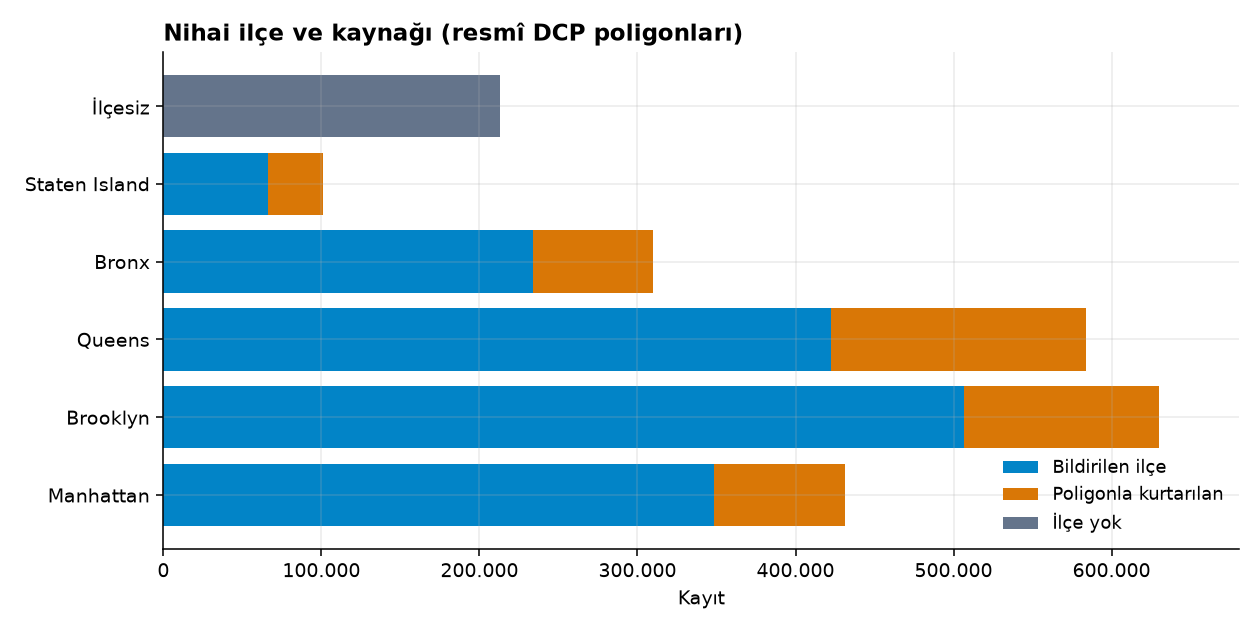

In [9]:
b = summary["boroughs"]
keys = ["original_missing", "recovered_by_polygon", "still_missing", "outside_polygons", "conflicts",
        "comparable_original_and_inferred", "conflict_pct_of_comparable"]
display(pd.Series({k: b[k] for k in keys}, name="değer").to_frame())
print("Hâlâ ilçesiz — nedenler:", b["still_missing_by_reason"])
print("Yüklem karşılaştırması:", c["predicate_comparison_unique_points"])
show("borough_inference.png")

Çelişki sayısı: 2365 | bildirilen ilçeye uzaklık (m): {'p50': 126.78423599936424, 'p90': 7045.349757845377, 'p99': 20618.566552341177, 'max': 34264.71389470155}
Kümülatif: {'10': 895, '50': 966, '100': 1103, '250': 1554, '500': 1706, '1000': 1786}


,latitude,longitude,borough_original,borough_inferred,records,distance_m,on_street,off_street
0,40.873642,-73.907970,BRONX,MANHATTAN,59,43.788251,NaN,NaN
1,40.875683,-73.908378,BRONX,MANHATTAN,58,137.661178,BROADWAY,WEST 228 STREET
2,40.713600,-74.009100,BROOKLYN,MANHATTAN,54,1594.542842,FLUSHING AVENUE,ATLANTIC AVENUE
3,40.733900,-73.954200,QUEENS,BROOKLYN,38,644.062748,168 STREET,90 AVENUE
4,40.875640,-73.908360,BRONX,MANHATTAN,32,134.848324,WEST 228 STREET,BROADWAY
5,40.877221,-73.909045,BRONX,MANHATTAN,32,96.334095,MARBLE HILL AVENUE,MARBLE HILL AVENUE
6,40.724400,-73.981800,QUEENS,MANHATTAN,31,2263.004563,130 STREET,90 AVENUE
7,40.713600,-74.009100,QUEENS,MANHATTAN,31,4818.162546,GRAND AVENUE,PINEVILLE LANE
8,40.699531,-73.911037,QUEENS,BROOKLYN,28,1.208650,MYRTLE AVENUE,WYCKOFF AVENUE
9,40.683190,-73.866300,BROOKLYN,QUEENS,20,0.275214,ATLANTIC AVENUE,ELDERTS LANE


Yedek geokodlama şüphesi: {'rule': 'aynı koordinatta >= 3 farklı bildirilmiş ilçe', 'locations': 15, 'records': 1844, 'records_by_year': {'2014': 1, '2015': 1, '2016': 853, '2017': 303, '2018': 268, '2019': 215, '2020': 82, '2021': 56, '2022': 29, '2023': 27, '2024': 9}}


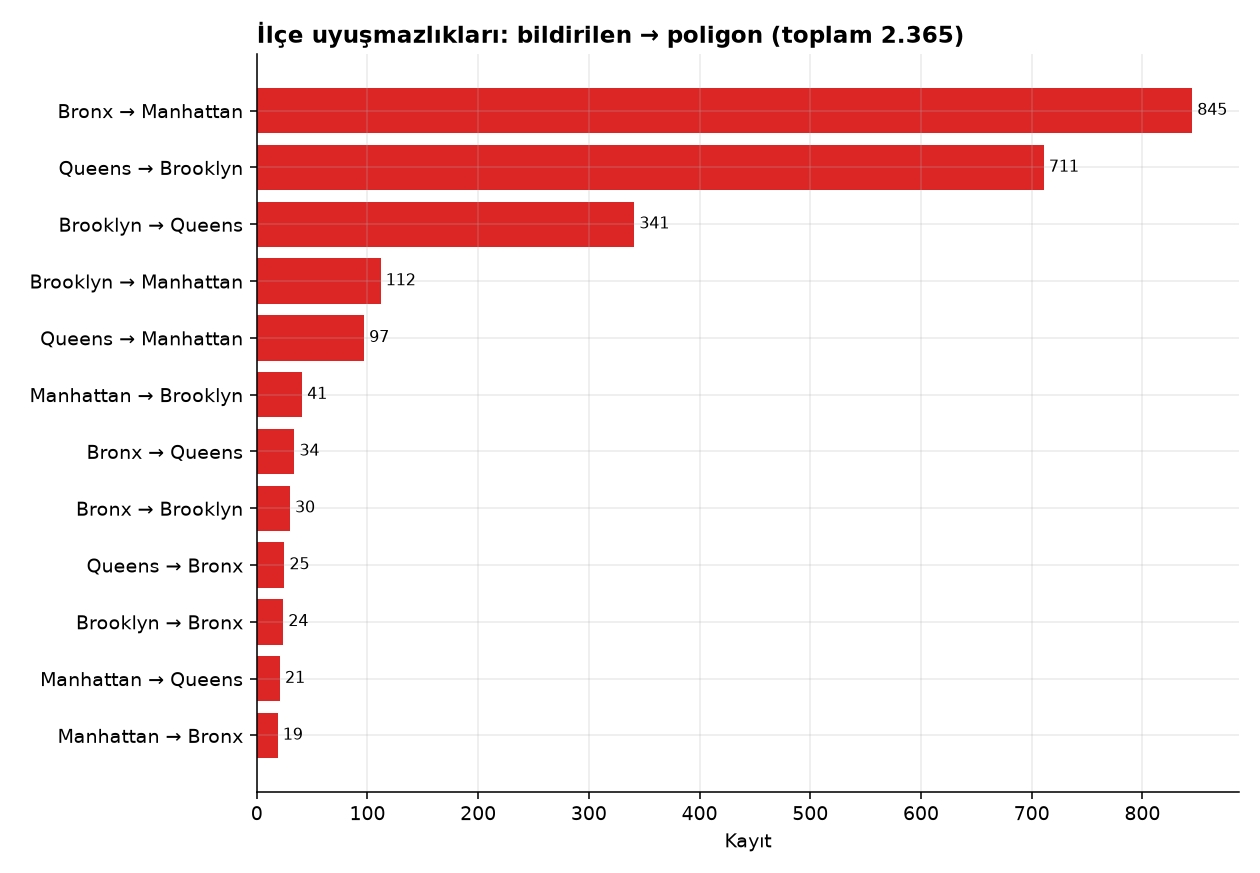

In [10]:
ca = c["conflict_analysis"]
print("Çelişki sayısı:", ca["count"], "| bildirilen ilçeye uzaklık (m):", ca["distance_to_reported_borough_m"])
print("Kümülatif:", ca["within_m"])
display(pd.DataFrame(ca["top_locations"]).head(10))
print("Yedek geokodlama şüphesi:", c["geocode_fallback"])
show("borough_conflicts.png")

**Yorum.** Çelişkiler üç farklı kaynaktan gelir: (1) ilçe sınırı caddelerinde metre altı mesafelerde kodlama
(ör. Brooklyn–Queens sınırı), (2) idari ve coğrafi ilçenin ayrıştığı yerler (Marble Hill: idari olarak
Manhattan, coğrafi olarak Bronx tarafında), (3) **bildirilen ilçeye kilometrelerce uzak** noktalar — aynı
koordinatta beş farklı ilçeden kayıt bulunan bu noktalar bir yedek/varsayılan geokodlama noktasına işaret eder.
Çelişkiler sessizce düzeltilmez: `borough_final` bildirilen değeri korur, `borough_conflict_flag` işaretlenir.

## 6. Tarih ve saat dönüşümleri

In [11]:
proc_cols = ["crash_date", "crash_time", "crash_year", "crash_month", "crash_day", "crash_hour", "crash_minute",
             "day_of_week", "is_weekend", "time_period", "hour_sin", "hour_cos", "month_sin", "month_cos",
             "midnight_suspect_flag", "coordinate_quality_status", "eligible_for_spatial_clustering",
             "geocode_fallback_suspect_flag", "latitude", "longitude", "lat_rad", "lon_rad", "x_m", "y_m",
             "borough_final", "vehicle_type_code1", "vehicle_category_1"]
proc = pd.read_parquet(paths["processed"], columns=proc_cols)
print(f"İşlenmiş katman: {len(proc):,} satır (seçili {len(proc_cols)} sütun); bellek tepe {peak_memory_mb()} MB")
proc[proc_cols[:14]].sample(5, random_state=0)

İşlenmiş katman: 2,269,187 satır (seçili 27 sütun); bellek tepe 904.6 MB


,crash_date,crash_time,crash_year,crash_month,crash_day,crash_hour,crash_minute,day_of_week,is_weekend,time_period,hour_sin,hour_cos,month_sin,month_cos
1916848,2022-08-07,17:01,2022,8,7,17,1,6,True,afternoon,-0.967046,-0.254602,-5.000000e-01,-8.660254e-01
1908163,2022-07-07,16:35,2022,7,7,16,35,3,False,afternoon,-0.932008,-0.362438,1.224647e-16,-1.000000e+00
1996901,2023-05-28,17:35,2023,5,28,17,35,6,True,afternoon,-0.994056,-0.108867,8.660254e-01,-5.000000e-01
368894,2018-12-02,11:50,2018,12,2,11,50,6,True,morning,0.043619,-0.999048,-5.000000e-01,8.660254e-01
2080443,2024-04-08,22:06,2024,4,8,22,6,0,False,evening,-0.477159,0.878817,1.000000e+00,6.123234e-17


In [12]:
# Döngüsel kodlamanın doğrulanması: birim çember üzerinde 23:59 ile 00:01 yakın, 00:00 ile 12:00 karşıt.
s, c_ = temporal.cyclical(np.array([23 + 59/60, 1/60, 0, 12]), 24)
print("23:59–00:01 uzaklığı:", round(float(np.hypot(s[0]-s[1], c_[0]-c_[1])), 4),
      "| 00:00–12:00 uzaklığı:", round(float(np.hypot(s[2]-s[3], c_[2]-c_[3])), 4))
print("Gerçek veride sin²+cos² = 1:", bool(np.allclose(proc["hour_sin"].dropna()**2 + proc["hour_cos"].dropna()**2, 1)))
display(pd.Series(summary["temporal"]["time_period_counts"], name="kayıt").to_frame().T)

23:59–00:01 uzaklığı: 0.0087 | 00:00–12:00 uzaklığı: 2.0
Gerçek veride sin²+cos² = 1: True


,afternoon,morning,evening,night
kayıt,862976,592449,573419,240343


## 7. Şüpheli 00:00 kayıtları

Şüpheli 00:00: 24,566 kayıt (%1.0826)
Tam saat yığılma oranı — 00:00: 28.29, diğer saatler medyan 13.31, en yüksek 15.71


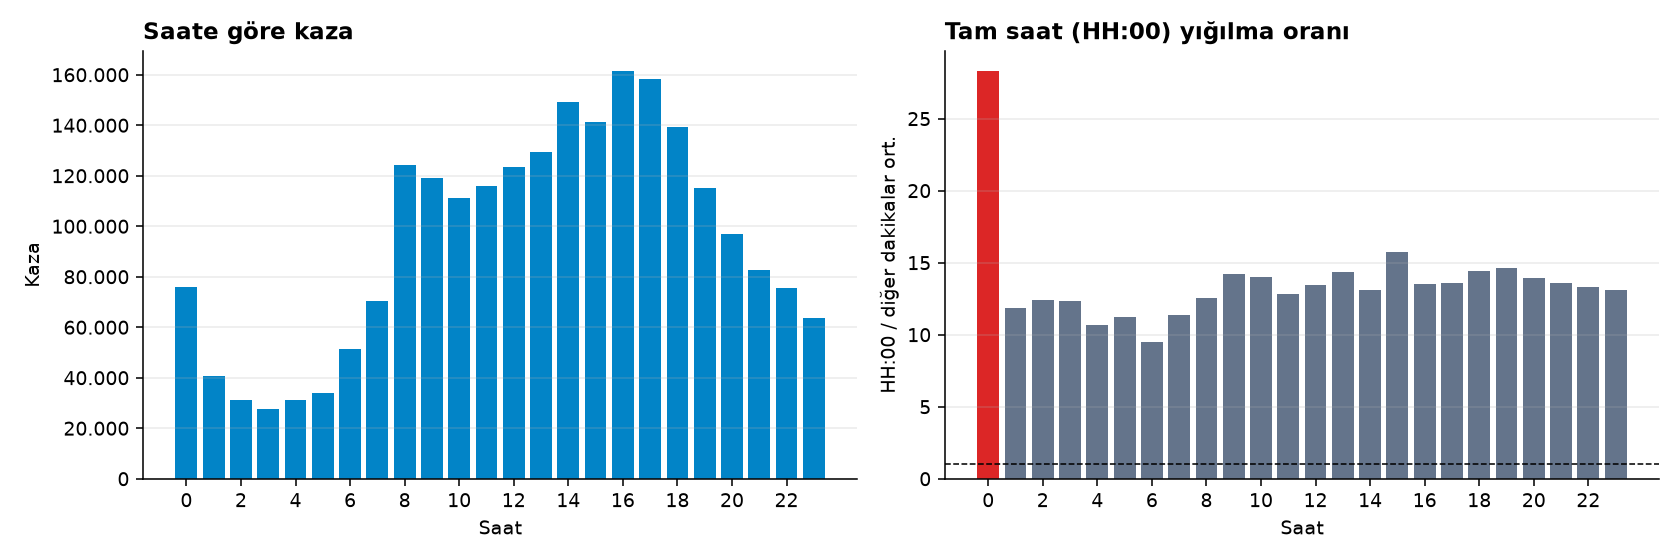

In [13]:
mh = summary["temporal"]["minute_heaping"]
print(f"Şüpheli 00:00: {summary['temporal']['midnight_suspect']:,} kayıt (%{summary['temporal']['midnight_suspect_pct']})")
print(f"Tam saat yığılma oranı — 00:00: {mh['midnight_ratio']}, diğer saatler medyan {mh['other_hours_ratio_median']}, "
      f"en yüksek {mh['other_hours_ratio_max']}")
show("hour_and_midnight.png")

**Karar ve gerekçe.** Tüm saatlerde tam saate (HH:00) belirgin bir yuvarlama alışkanlığı vardır; 00:00'daki
yığılma ise bu genel düzeyin yaklaşık iki katıdır. Bu, 00:00 kayıtlarının bir kısmının "saat bilinmiyor"
yer tutucusu olabileceğini gösterir — ama hangilerinin olduğunu ayırt etmek mümkün değildir. Bu yüzden:
kayıtlar **silinmez ve saatleri değiştirilmez**; `midnight_suspect_flag` ile işaretlenir. Yalnızca mekânsal
modeller (A, B, C) saati kullanmadığından etkilenmez; zaman kullanan D deneyi için 00:00 hariç bir
**duyarlılık seti** ayrıca üretilmiştir.

## 8. Araç türü standardizasyonu

Ham farklı etiket 3,149 -> normalize 2,165 -> üst kategori 12; eşleşmeyen etiket 1,473 (geçişlerin %0.135)


,rule,category,pattern
0,unknown_tokens,UNKNOWN,^(UNKNOWN( VE.*)?|UNK|UNKN|UNKNO|UNKOW|N/?A|NONE|UNSPECIFIED)$
1,emergency,EMERGENCY,AMBUL|^AMBU$|^AMB$|^EMS$|FDNY|FIRE|^POLI|POLICE|^RMP$|NYPD|NYS AMBULA
2,e_micromobility,E_MICROMOBILITY,^E[- ]?BIK|^EBIK|^E[- ]?SCO|E-SCOOTER|^ELECTRIC S|^E-SKATE|^ESKATE...
3,bus,BUS,\bBUS\b|^SCHOO|^MTA B
4,taxi_for_hire,TAXI_FOR_HIRE,TAXI|^CAB$|LIVERY|^LIMO|^YELLO|^GREEN TAXI|FOR HIRE
5,motorcycle,MOTORCYCLE,MOTORCYCLE|MOTORBIKE|^MOPE?D|MOTORSCOOT|MOTOR SCOO|^MOTOR$|MINIBIK...
6,bicycle,BICYCLE,^BIKE$|BICYCLE|^BICY|^BIKE
7,suv,SUV,SPORT UTILITY|STATION WAGON|^SUV$|^SUBN$|^SUBUR|^CARRY ALL$|^WAGON$
8,passenger_car,PASSENGER_CAR,SEDAN|PASSENGER VEHICLE|^PASSENGER$|^PASS$|^PAS$|CONVERTIBLE|^3-DO...
9,refrigerated_truck,TRUCK_COMMERCIAL,REFRIGERATED|^REFG


,normalized,count,raw_variants,category,rule,category_tr
0,SEDAN,1178755,3,PASSENGER_CAR,passenger_car,Binek otomobil
1,STATION WAGON/SPORT UTILITY VEHICLE,938050,1,SUV,suv,SUV / station wagon
2,PASSENGER VEHICLE,769982,1,PASSENGER_CAR,passenger_car,Binek otomobil
3,SPORT UTILITY / STATION WAGON,337507,1,SUV,suv,SUV / station wagon
4,TAXI,160983,3,TAXI_FOR_HIRE,taxi_for_hire,Taksi / kiralık araç
5,UNKNOWN,105651,3,UNKNOWN,unknown_tokens,Bilinmiyor
6,PICK-UP TRUCK,100998,2,TRUCK_COMMERCIAL,truck_commercial,Kamyon / ticari
7,4 DR SEDAN,79609,1,PASSENGER_CAR,passenger_car,Binek otomobil
8,BUS,74682,4,BUS,bus,Otobüs
9,VAN,71157,5,VAN,van,Van / minibüs


,normalized,count,raw_variants,category,rule,category_tr
37,STANDING S,1413,4,OTHER,unmatched,Diğer
68,UN/C,245,1,OTHER,unmatched,Diğer
73,ESST,199,1,OTHER,unmatched,Diğer
89,PALLET,138,1,OTHER,unmatched,Diğer
90,ELECT,135,3,OTHER,unmatched,Diğer
93,UN/T,121,1,OTHER,unmatched,Diğer
119,STREE,63,3,OTHER,unmatched,Diğer
122,FORD,58,3,OTHER,unmatched,Diğer
131,C1,50,2,OTHER,unmatched,Diğer
137,UN/V,49,1,OTHER,unmatched,Diğer


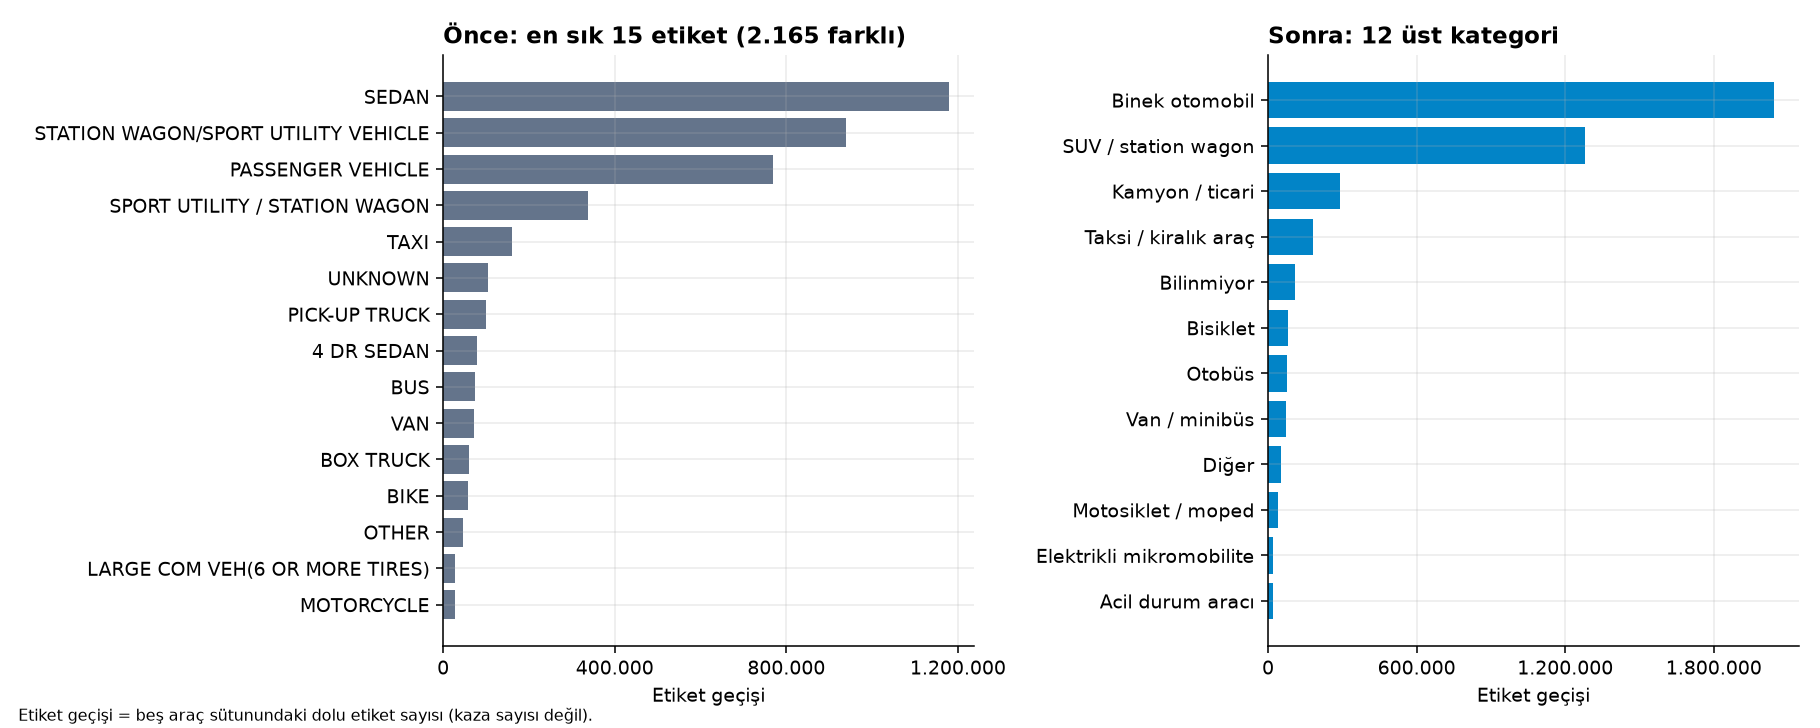

In [14]:
mapping = pd.read_parquet(paths["mapping"])
v = summary["vehicles"]
print(f"Ham farklı etiket {v['raw_distinct_labels']:,} -> normalize {v['normalized_distinct_labels']:,} -> "
      f"üst kategori {v['category_count']}; eşleşmeyen etiket {v['unmatched_labels']:,} "
      f"(geçişlerin %{v['unmatched_mentions_pct']})")
display(pd.DataFrame(v["rules"]))
display(mapping.head(20))
display(mapping[mapping["rule"] == "unmatched"].head(10))
show("vehicle_categories_before_after.png")

**Yorum.** Kurallar sıralıdır ve ilk eşleşen kazanır (ör. *E-BIKE* bisiklet değil elektrikli mikromobilite;
*FDNY TRUCK* kamyon değil acil durum aracı). Anlamı belirsiz kısaltmalar (ör. *UN/C*, *STANDING S*) bir
kategoriye zorla atanmaz: `OTHER` altında `unmatched` kuralıyla tutulur. Tam tablo
`reports/phase2/vehicle_type_mapping.csv` dosyasındadır.

## 9. Yaralanma ve ölüm tutarlılığı

In [15]:
cas = summary["casualties"]
display(pd.DataFrame({"Yaralı": cas["injury"]["flag_counts"], "Ölü": cas["fatality"]["flag_counts"]}))
print("has_reported_injury:", cas["injury"]["has_reported"], "| has_reported_fatality:", cas["fatality"]["has_reported"])
print("Yaralı: toplam alanı - alt alanlar farkının dağılımı:", dict(list(cas["injury"]["difference_distribution"].items())[:12]))

,Yaralı,Ölü
negative_value,0,0
total_missing,18,8913
component_missing,0,0
total_lt_components,227,6
total_gt_components,10687,78
ok,2258255,2260190


has_reported_injury: 558805 | has_reported_fatality: 3494
Yaralı: toplam alanı - alt alanlar farkının dağılımı: {'-14': 1, '-7': 1, '-6': 1, '-5': 3, '-4': 12, '-3': 27, '-2': 78, '-1': 104, '1': 10089, '2': 527, '3': 47, '4': 17}


**Neden ana coğrafi modelde kullanılmıyor?** Yaralanma/ölüm sayıları **sonuç** değişkenleridir. Üyeliği
belirlemeleri durumunda kümeler "kaza yoğunluğu" yerine "şiddet ağırlıklı yoğunluk" olur, nadir ölüm
olayları sınırları orantısız etkiler ve sonra kümeleri aynı değişkenle betimlemek döngüsel bir akıl
yürütmeye dönüşür. Bu alanlar ham hâlleriyle korunur ve kümelerin **profilini** çıkarmak için kullanılacaktır.

## 10. Tekrarlanan koordinatlar

Uygun kayıt 2,020,638; benzersiz konum 349,122; konum başına ort. 5.788, maks. 887


,locations,records
1,199956,199956
2–5,85280,238627
6–10,22111,169335
11–50,35127,778910
51–100,4716,322642
>100,1932,311168


,locations,records
min_samples,,
5,72012,1622685
10,44920,1444170
20,23820,1154779
50,6889,645860
100,1980,315968


,location_id,latitude,longitude,weight,borough,on_street_name,off_street_name
0,32977,40.608757,-74.038086,887,NaN,VERRAZANO BRIDGE UPPER,NaN
1,151642,40.696033,-73.984530,712,BROOKLYN,TILLARY STREET,TILLARY STREET
2,328417,40.861862,-73.912820,685,BRONX,WEST FORDHAM ROAD,MAJOR DEEGAN EXPRESSWAY
3,283380,40.804700,-73.912430,597,BRONX,BRUCKNER BOULEVARD,EAST 138 STREET
4,151646,40.696035,-73.984529,587,BROOKLYN,TILLARY STREET,FLATBUSH AVENUE EXTENSION
5,116241,40.675735,-73.896860,581,BROOKLYN,PENNSYLVANIA AVENUE,ATLANTIC AVENUE
6,90134,40.658577,-73.890630,527,BROOKLYN,PENNSYLVANIA AVENUE,LINDEN BOULEVARD
7,28199,40.604153,-74.051980,510,NaN,VERRAZANO BRIDGE UPPER,NaN
8,280294,40.798256,-73.827440,477,NaN,BRONX WHITESTONE BRIDGE,NaN
9,253194,40.760601,-73.964314,474,MANHATTAN,EAST 59 STREET,2 AVENUE


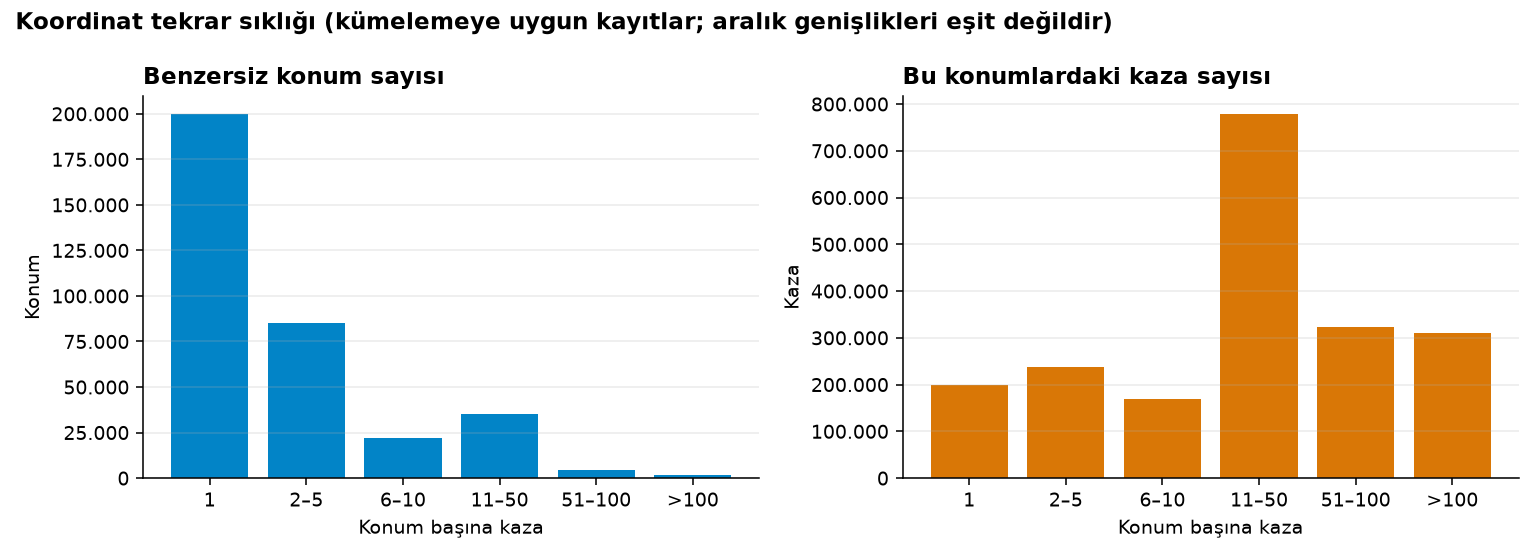

In [16]:
r = summary["repetition"]
print(f"Uygun kayıt {r['eligible_records']:,}; benzersiz konum {r['unique_locations']:,}; "
      f"konum başına ort. {r['records_per_location_mean']}, maks. {r['records_per_location_max']}")
display(pd.DataFrame(r["distribution"]).T)
display(pd.DataFrame(r["self_core_locations_by_min_samples"]).T.rename_axis("min_samples"))
display(pd.DataFrame(r["top_locations"]).head(12))
show("coordinate_repetition.png")

**DBSCAN'e etkisi ve Faz 3 stratejisi.** Aynı koordinattaki farklı `collision_id`'ler ayrı olaylardır ve
silinmez. DBSCAN'de ağırlığı `min_samples` değerine ulaşan bir konum, `eps` ne olursa olsun **tek başına
çekirdek noktadır**; yukarıdaki tablo bunun kaç konumu etkilediğini gösterir — `min_samples` seçimi bu
yüzden kritik bir parametredir. Performans için benzersiz konum + ağırlık temsili hazırlanmıştır:
scikit-learn `DBSCAN.fit(X, sample_weight=w)` ve `KMeans.fit(X, sample_weight=w)` olay sayısını korur;
**`HDBSCAN.fit` ise `sample_weight` desteklemez**, bu yüzden C modeli kayıt düzeyinde çalıştırılmalıdır.
Testlerde (sentetik veri) ağırlıklı DBSCAN'in kayıt düzeyiyle aynı bölümlemeyi verdiği doğrulanmıştır.

## 11. Modelleme için koordinat temsilleri

In [17]:
pj = summary["coordinates"]["projection_check"]
display(pd.Series(pj, name="değer").to_frame())
e = proc[proc["eligible_for_spatial_clustering"]]
i, j = 0, 1_000
hav = coordinates.haversine_m(e["latitude"].iloc[i], e["longitude"].iloc[i], e["latitude"].iloc[j], e["longitude"].iloc[j])
euc = float(np.hypot(e["x_m"].iloc[i] - e["x_m"].iloc[j], e["y_m"].iloc[i] - e["y_m"].iloc[j]))
from sklearn.metrics.pairwise import haversine_distances
skl = haversine_distances(e[["lat_rad", "lon_rad"]].iloc[[i, j]].to_numpy())[0, 1] * coordinates.EARTH_RADIUS_M
print(f"Örnek çift: Haversine {hav:,.1f} m | sklearn haversine (lat_rad, lon_rad) {skl:,.1f} m | UTM Öklid {euc:,.1f} m")
for eps_m in (50, 100, 200):
    print(f"eps = {eps_m} m  ->  eps_rad = {coordinates.meters_to_radians(eps_m):.3e}")

,değer
crs,EPSG:32618
crs_name,WGS 84 / UTM zone 18N
area_of_use,"[-78.0, 0.0, -72.0, 84.0]"
all_inside_area_of_use,True
points_outside_area_of_use,0
roundtrip_error_m_max,0.0
pair_sample,19998
reference,WGS84 elipsoidi jeodezik mesafe (pyproj.Geod)
projection_rel_error_median,0.000298
projection_rel_error_max,0.000345


Örnek çift: Haversine 17,494.9 m | sklearn haversine (lat_rad, lon_rad) 17,494.9 m | UTM Öklid 17,470.7 m
eps = 50 m  ->  eps_rad = 7.848e-06
eps = 100 m  ->  eps_rad = 1.570e-05
eps = 200 m  ->  eps_rad = 3.139e-05


**Normalizasyon/ölçekleme yapıldı mı?** Hayır, bilinçli olarak. A ve C'de girdi radyandır ve Haversine
metriği mesafeyi doğrudan küre üzerinde hesaplar; B'de girdi her iki eksende de metredir. Z-skoru gibi
bir ölçekleme, enlem ve boylam eksenlerini farklı katsayılarla esneterek gerçek mesafeyi bozar ve `eps`
değerinin metre karşılığını anlamsız kılardı.

## 12. Öznitelik seçimi

In [18]:
fs_table = pd.read_csv(config.REPORTS_DIR / "phase2" / "feature_selection.csv")
display(fs_table[["Öznitelik", "Köken", "Eksik %", "Modeller", "Dahil edilmeme nedeni"]])
print("Model girdisi olan öznitelikler:", sorted(fs_table.loc[fs_table["Modeller"] != "—", "Öznitelik"]))

,Öznitelik,Köken,Eksik %,Modeller,Dahil edilmeme nedeni
0,collision_id,raw,0.0000,—,"Kimlik; mekânsal/zamansal bilgi taşımaz, modele girerse anlamsız m..."
1,crash_date,raw,0.0000,—,Ham tarih doğrudan girmez; türetilmiş eksenler (days_since_epoch) ...
2,crash_time,raw,0.0000,—,Metin; türetilmiş döngüsel saat D'de kullanılır
3,borough_original,raw,30.4680,—,Konumun türevi (çift temsil) ve %30 eksik; modele eklenirse coğraf...
4,zip_code,raw,30.4824,—,"Konumun kaba türevi, %30 eksik"
...,...,...,...,...,...
60,fatality_data_quality_flag,engineered,0.0000,—,Kalite bayrağı
61,has_reported_injury,engineered,0.0000,—,Sonuç değişkeni
62,has_reported_fatality,engineered,0.0000,—,Sonuç değişkeni
63,vehicle_category_1..5,engineered,0.7527,—,Kategorik; mekânsal soruya ait değil


Model girdisi olan öznitelikler: ['days_since_epoch', 'dow_cos', 'dow_sin', 'hour_cos', 'hour_sin', 'lat_rad', 'latitude', 'lon_rad', 'longitude', 'x_m', 'y_m']


29 ham sütunun hiçbiri körü körüne model girdisi yapılmamıştır. Coğrafi modellerin (A, B, C) girdisi
yalnızca **konumdur** (uygun birimlerde iki boyut). Gerekçe: araştırma sorusu mekânsal yoğunlaşmadır;
kimlikler anlamsız mesafe üretir; ilçe/posta kodu/sokak adı konumun türevleri veya metin tekrarlarıdır;
araç/faktör kategorik ve mekânsal soruya ait değildir; yaralanma/ölüm sonuç değişkenidir. Bu alanlar
filtre ve küme yorumu için korunur. Ayrıntılı tablo: `docs/feature_selection_report.md`.

## 13. Model A/B/C/D için hazırlanan veri yapıları

,model,level,key,features,weight,rows,weight_sum,all_finite,metric
A_dbscan_haversine,DBSCAN (A),record,collision_id,"[lat_rad, lon_rad]",NaN,2020638,None,True,"haversine (scikit-learn: [enlem, boylam] radyan)"
A_dbscan_haversine_weighted,"DBSCAN (A, ağırlıklı)",unique_location,location_id,"[lat_rad, lon_rad]",weight,349122,2020638,True,"haversine; fit(X, sample_weight=weight)"
B_kmeans_projected,K-Means (B),record,collision_id,"[x_m, y_m]",NaN,2020638,None,True,Öklid (EPSG:32618 metre)
B_kmeans_projected_weighted,"K-Means (B, ağırlıklı)",unique_location,location_id,"[x_m, y_m]",weight,349122,2020638,True,"Öklid; fit(X, sample_weight=weight)"
C_hdbscan_haversine,HDBSCAN (C),record,collision_id,"[lat_rad, lon_rad]",NaN,2020638,None,True,haversine (alternatif: x_m/y_m Öklid)
D_spatiotemporal_experimental,"Uzay-zaman (D, deneysel)",record,collision_id,"[x_m, y_m, days_since_epoch, hour_sin, hour_cos, dow_sin, dow_cos]",NaN,2020638,None,True,Ayrı eşikli komşuluk: mesafe_m <= eps_s VE |Δgün| <= eps_t (VE ist...
D_spatiotemporal_experimental_no_midnight,"Uzay-zaman (D, duyarlılık: 00:00 hariç)",record,collision_id,"[x_m, y_m, days_since_epoch, hour_sin, hour_cos, dow_sin, dow_cos]",NaN,1997922,None,True,D ile aynı


A_dbscan_haversine (2020638, 3) ['collision_id', 'lat_rad', 'lon_rad']


,collision_id,lat_rad,lon_rad
0,4406876,0.710811,-1.290712
1,4407150,0.709974,-1.291580
2,4406940,0.709956,-1.288535


A_dbscan_haversine_weighted (349122, 4) ['location_id', 'lat_rad', 'lon_rad', 'weight']


,location_id,lat_rad,lon_rad,weight
0,0,0.706840,-1.295809,1
1,1,0.706840,-1.295809,2
2,2,0.706843,-1.295793,1


B_kmeans_projected

 (2020638, 3) ['collision_id', 'x_m', 'y_m']


,collision_id,x_m,y_m
0,4406876,588474.677332,4.508918e+06
1,4407150,584332.009041,4.503550e+06
2,4406940,599080.722718,4.503618e+06


D_spatiotemporal_experimental (2020638, 9) ['collision_id', 'x_m', 'y_m', 'days_since_epoch', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'midnight_suspect_flag']


,collision_id,x_m,y_m,days_since_epoch,hour_sin,hour_cos,dow_sin,dow_cos,midnight_suspect_flag
0,4406876,588474.677332,4.508918e+06,18730,0.0,1.0,0.781831,0.62349,True
1,4407150,584332.009041,4.503550e+06,18730,0.0,1.0,0.781831,0.62349,True
2,4406940,599080.722718,4.503618e+06,18730,0.0,1.0,0.781831,0.62349,True


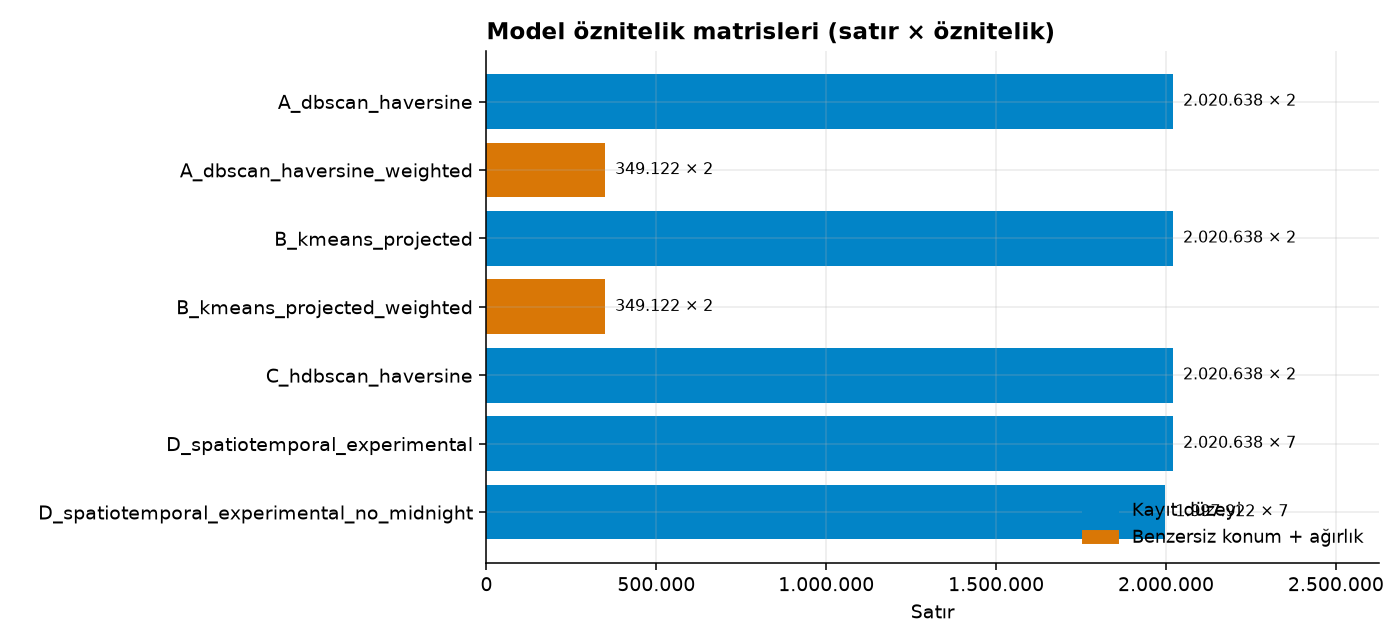

In [19]:
fsets = pd.DataFrame(summary["feature_sets"]).T[["model", "level", "key", "features", "weight", "rows",
                                                 "weight_sum", "all_finite", "metric"]]
display(fsets)
for name in ("A_dbscan_haversine", "A_dbscan_haversine_weighted", "B_kmeans_projected", "D_spatiotemporal_experimental"):
    f = pd.read_parquet(paths[f"feature:{name}"])
    print(name, f.shape, list(f.columns)); display(f.head(3))
show("feature_sets.png")

**Model D (deneysel) mesafe tanımı.** Metre ile gün/saat tek bir ağırlıklı toplamda birleştirilmez (keyfi
bir ölçek katsayısı gerektirirdi). Bunun yerine ST-DBSCAN benzeri **ayrı eşikli** komşuluk önerilir:
`mesafe_m ≤ eps_s` **ve** `|Δgün| ≤ eps_t` (isteğe bağlı olarak döngüsel saat farkı ≤ `eps_h`). Bu model
farklı bir soruyu (uzay-zamanda yoğunlaşma) yanıtladığından A/B/C ile aynı değerlendirme bağlamında
doğrudan adil karşılaştırılamaz; ayrı raporlanacaktır.

## 14. Temizleme öncesi / sonrası karşılaştırması

In [20]:
cc = summary["phase1_crosscheck"]
before_after = pd.DataFrame({
    "Önce (ham / Faz 1)": {
        "Toplam kayıt": summary["rows"]["raw"],
        "Kullanılabilir koordinat (kaba kutu)": cc["valid_coordinates_bbox"]["phase2"],
        "İlçe bilgisi olan kayıt": summary["rows"]["raw"] - b["original_missing"],
        "Araç türü farklı değer": v["raw_distinct_labels"],
        "Silinen kayıt": 0,
    },
    "Sonra (Faz 2)": {
        "Toplam kayıt": summary["rows"]["processed"],
        "Kullanılabilir koordinat (kaba kutu)": summary["rows"]["eligible_for_spatial_clustering"],
        "İlçe bilgisi olan kayıt": summary["rows"]["processed"] - b["still_missing"],
        "Araç türü farklı değer": v["category_count"],
        "Silinen kayıt": summary["rows"]["raw"] - summary["rows"]["processed"],
    },
})
before_after.index = before_after.index.str.replace("Kullanılabilir koordinat (kaba kutu)",
                                                    "Kümelemede kullanılabilir koordinat")
before_after

,Önce (ham / Faz 1),Sonra (Faz 2)
Toplam kayıt,2269187,2269187
Kümelemede kullanılabilir koordinat,2020640,2020638
İlçe bilgisi olan kayıt,1577812,2056092
Araç türü farklı değer,3149,12
Silinen kayıt,0,0


## 15. Faz 3 hazırlık değerlendirmesi

**Hazır olanlar:** dört modelin öznitelik matrisleri (kayıt düzeyi ve ağırlıklı benzersiz konum), her
dosyanın kaynak/yapılandırma/satır sayısı yan kayıtları, ilçe ve tarih filtreleri için zenginleştirilmiş
işlenmiş katman, kalite bayrakları (00:00, yedek geokodlama, ilçe çelişkisi, yaralanma tutarlılığı).

**Faz 3'te dikkat edilecekler**
- `min_samples` seçimi: tek başına çekirdek olan konum sayısı (§10) parametre duyarlılığında raporlanmalı.
- Ağırlıklı DBSCAN'in kayıt düzeyiyle eşdeğerliği gerçek verinin bir alt örnekleminde birebir doğrulanmalı.
- HDBSCAN kayıt düzeyinde çalıştırılmalı; bellek/süre ölçülmeli (gerekirse belgelenmiş alt örneklem).
- Yedek geokodlama şüphesi olan kayıtlarla ve onlarsız duyarlılık analizi yapılmalı.
- Siluet/Davies–Bouldin gürültü dışlanarak ve Haversine ile tutarlı biçimde hesaplanmalı.

In [21]:
print(f"Defter tamamlandı. Süreç bellek tepe değeri: {peak_memory_mb()} MB")

Defter tamamlandı. Süreç bellek tepe değeri: 1387.9 MB
